# Sections 4.1 & 4.2: Graphs and Graph Modeling

**Topics:** Graph basics and adjacency representations, Degree and neighbors, Graph traversal, Graph and graph modeling

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1vAAQVMdkjLEtMmY69aLa8CNkNBdXERGJ?usp=sharing)

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque

## Graph basics and adjacency representations

Graphs help us understand the interactions between nodes, using adjacency representations to represent the edge-node relationship. We can verify the degree values and adjacency matrix to understand interactions.

In [56]:
# 10x10 adjacency matrix, using 10 different nodes and 14 edges.
nodes = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"]
edges = [("A","B"), ("A","C"), ("B","D"), ("C","D"), ("D","E"), ("E","F"), ("F","G"), ("G","H"), ("H","I"), ("I","J"), ("A","J"), ("C","H"), ("E","J")]
# Checking index and adjacency matrices.
index = {node: i for i, node in enumerate(nodes)}
adj = np.zeros((len(nodes), len(nodes)), dtype=int)
for u, v in edges:
    adj[index[u], index[v]] = 1
    adj[index[v], index[u]] = 1
# Print out adjaency matrix and degree amounts
print("Adjacency matrix,", adj)
print("Degrees:", dict(zip(nodes, adj.sum(axis=1))))


Adjacency matrix, [[0 1 1 0 0 0 0 0 0 1]
 [1 0 0 1 0 0 0 0 0 0]
 [1 0 0 1 0 0 0 1 0 0]
 [0 1 1 0 1 0 0 0 0 0]
 [0 0 0 1 0 1 0 0 0 1]
 [0 0 0 0 1 0 1 0 0 0]
 [0 0 0 0 0 1 0 1 0 0]
 [0 0 1 0 0 0 1 0 1 0]
 [0 0 0 0 0 0 0 1 0 1]
 [1 0 0 0 1 0 0 0 1 0]]
Degrees: {'A': np.int64(3), 'B': np.int64(2), 'C': np.int64(3), 'D': np.int64(3), 'E': np.int64(3), 'F': np.int64(2), 'G': np.int64(2), 'H': np.int64(3), 'I': np.int64(2), 'J': np.int64(3)}


## Degree and neighbors

Degrees and neighbors show the relationship between nodes, helping to track what paths are able to take. Depth First-Search and Breadth First-Search use degrees and neighbors to prioritize which path an algorithm takes to optimize cost and duration. In this case, we demonstrate the difference between a bfs and a dfs relationship here using a graph.

Adjacency list: {'A': ['B', 'C'], 'B': ['A', 'D'], 'C': ['A', 'D'], 'D': ['B', 'C', 'E'], 'E': ['D']}
Degrees: {'A': 2, 'B': 2, 'C': 2, 'D': 3, 'E': 1}
BFS order from A: ['A', 'B', 'C', 'D', 'E']
DFS order from A: ['A', 'C', 'D', 'E', 'B']


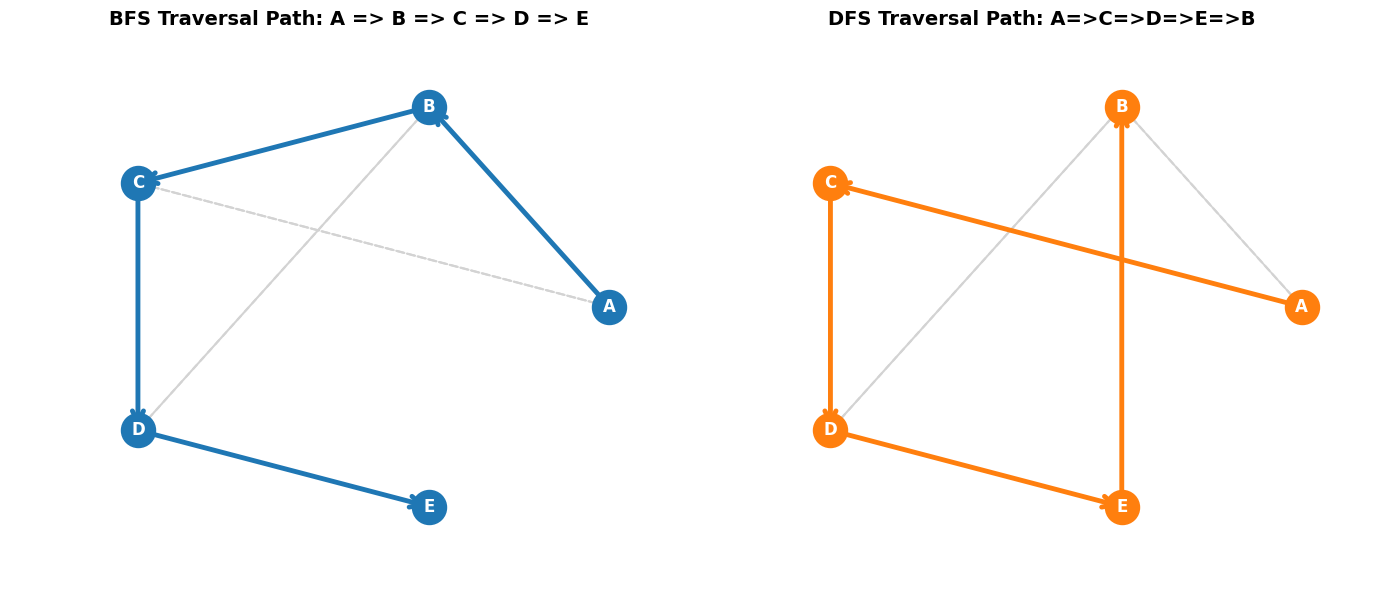

In [52]:
adj_list = {node: [] for node in nodes}
for u, v in edges:
    adj_list[u].append(v)
    adj_list[v].append(u)

def bfs(start):
    seen = {start}
    order = []
    queue = deque([start])
    while queue:
        node = queue.popleft()
        order.append(node)
        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                queue.append(neighbor)
    return order

def dfs(start):
    seen = {start}
    order = []
    stack = [start]
    while stack:
        node = stack.pop()
        order.append(node)
        for neighbor in adj_list[node]:
            if neighbor not in seen:
                seen.add(neighbor)
                stack.append(neighbor)
    return order

print("Adjacency list:", adj_list)
print("Degrees:", dict(zip(nodes, [len(adj_list[node]) for node in nodes])))

print("BFS order from A:", bfs("A"))
print("DFS order from A:", dfs("A"))

theta = np.linspace(0, 2 * np.pi, len(nodes), endpoint=False)
pos = {node: (np.cos(t), np.sin(t)) for node, t in zip(nodes, theta)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# BFS Traversal Path:
ax1.set_title("BFS Traversal Path: A => B => C => D => E", fontsize=14, fontweight="bold")
for u, v in edges:
  # Create Arrows for visualization
    ax1.annotate("", xy=(pos[v][0], pos[v][1]), xytext=(pos[u][0], pos[u][1]),
                 arrowprops=dict(arrowstyle="->", color="lightgray", lw=1.5, ls="--"), zorder=1)
    ax1.annotate("", xy=(pos[u][0], pos[u][1]), xytext=(pos[v][0], pos[v][1]),
                 arrowprops=dict(arrowstyle="->", color="lightgray", lw=1.5, ls="--"), zorder=1)
for i in range(len(bfs("A")) - 1):
    u, v = bfs("A")[i], bfs("A")[i+1]
    ax1.annotate("", xy=(pos[v][0], pos[v][1]), xytext=(pos[u][0], pos[u][1]),
                 arrowprops=dict(arrowstyle="->", color="tab:blue", lw=3.5, mutation_scale=20), zorder=2)
for node, (x, y) in pos.items():
    ax1.scatter(x, y, color="tab:blue", s=600, zorder=3)
    ax1.text(x, y, node, color="white", ha="center", va="center", fontsize=12, fontweight="bold", zorder=4)
ax1.set_xlim(-1.3, 1.3)
ax1.set_ylim(-1.3, 1.3)
ax1.axis("off")

# DFS Path Visualization
ax2.set_title("DFS Traversal Path: A=>C=>D=>E=>B", fontsize=14, fontweight="bold")
for u, v in edges:
    # Create Arrows for visualization
    ax2.annotate("", xy=(pos[v][0], pos[v][1]), xytext=(pos[u][0], pos[u][1]),
                 arrowprops=dict(arrowstyle="->", color="lightgray", lw=1.5, ls="--"), zorder=1)
    ax2.annotate("", xy=(pos[u][0], pos[u][1]), xytext=(pos[v][0], pos[v][1]),
                 arrowprops=dict(arrowstyle="->", color="lightgray", lw=1.5, ls="--"), zorder=1)
for i in range(len(dfs('A')) - 1):
    u, v = dfs('A')[i], dfs('A')[i+1]
    ax2.annotate("", xy=(pos[v][0], pos[v][1]), xytext=(pos[u][0], pos[u][1]),
                 arrowprops=dict(arrowstyle="->", color="tab:orange", lw=3.5, mutation_scale=20), zorder=2)
for node, (x, y) in pos.items():
    ax2.scatter(x, y, color="tab:orange", s=600, zorder=3)
    ax2.text(x, y, node, color="white", ha="center", va="center", fontsize=12, fontweight="bold", zorder=4)
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.axis("off")

plt.tight_layout()
plt.show()

## Graph traversal

Graph traversal deals with the idea of finding the most efficient way to pass through each position. Given a set of positions, the goal is to find the fastest way tovisit each point while focusing on minimizing loss. Here, we will demonstrate a classic case of graph traversal using the traveling salesman problem.


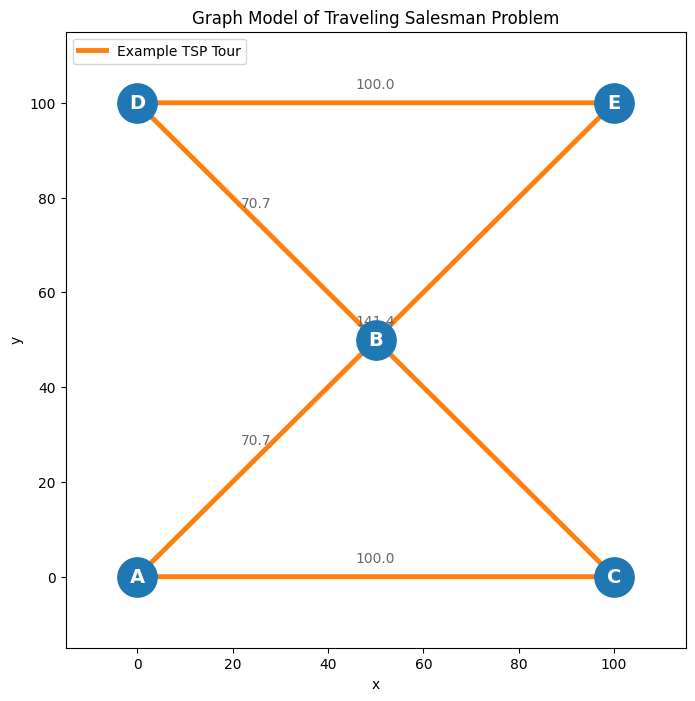

In [13]:
import math

traveling_salesman_problem = {
    "A": (0,0),
    "B": (50,50),
    "C": (100, 0),
    "D": (0, 100),
    "E": (100, 100)
}
plt.figure(figsize=(8,8))

for u, v in edges:
    p1 = traveling_salesman_problem[u]
    p2 = traveling_salesman_problem[v]
    distance = math.sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)
    plt.plot([p1[0], p2[0]], [p1[1], p2[1]], color="lightgray", linestyle="--", linewidth=2, zorder=1)

    mid_x = (p1[0] + p2[0]) / 2
    mid_y = (p1[1] + p2[1]) / 2
    plt.text(mid_x, mid_y + 3, f"{distance:.1f}", color="dimgray", fontsize=10, ha="center")

tour = ["A", "B", "E", "D", "C", "A"]
tour_x = [traveling_salesman_problem[node][0] for node in tour]
tour_y = [traveling_salesman_problem[node][1] for node in tour]
plt.plot(tour_x, tour_y, color="tab:orange", linewidth=3.5, label="Example TSP Tour", zorder=2)

for node, (x, y) in traveling_salesman_problem.items():
    plt.scatter(x, y, s=800, color="tab:blue", zorder=3)
    plt.text(x, y, node, color="white", ha="center", va="center", fontsize=14, fontweight="bold", zorder=4)

plt.legend(loc="upper left")
plt.xlim(-15, 115)
plt.ylim(-15, 115)
plt.title("Graph Model of Traveling Salesman Problem")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

## Graph and graph modeling

Graph and graph modeling can be used to visually represent probabilties of real-life uncertanties. For instance, predicting whether a person might be infected is useful in this field, as graph and graph modeling can monitor if an infection has spread. In this case, we can show a case of graph and graph modeling to monitor signs of COVID-19.

In [29]:
# 10 Nodes, for each person
n10 = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"]
# 12 edges, serving as connections of each person as a node.
e10 = [
    ("A", "B"), ("A", "C"), ("B", "D"), ("C", "D"), ("D", "E"),
    ("E", "F"), ("F", "G"), ("G", "H"), ("H", "I"), ("I", "J"),
    ("A", "J"), ("C", "H"), ("E", "J")
]
# Appends the nodes and edges, and checks for whether each person has a covid symptom.
covid_10 = {node: [] for node in n10}
for u, v in e10:
    covid_10[u].append(v)
    covid_10[v].append(u)
# Checks for suspectibility or infected states.
has_covid = {
    "A": "infected", "B": "susceptible", "C": "susecptible", "D": "susecptible", "E": "susecptible",
    "F": "susecptible", "G": "susecptible", "H": "infected", "I": "susecptible", "J": "infected"
}
# Monitors risk score.
risk_scores = {}
for node in n10:
    infected_neighbors = sum(has_covid[n] == "infected" for n in covid_10[node])
    risk_scores[node] = infected_neighbors / max(1, len(covid_10[node]))

# Format and store the scores on a single line
risk_score = ", ".join([f"{node}: {score:.2f}" for node, score in risk_scores.items()])
print("Risk scores:", risk_score)

Risk scores: A: 0.33, B: 0.50, C: 0.67, D: 0.00, E: 0.33, F: 0.00, G: 0.50, H: 0.00, I: 1.00, J: 0.33
